# Why random splits overstate sign recognition accuracy

Live app: [https://swapnil007-curious.github.io/manuvox/](https://swapnil007-curious.github.io/manuvox/) · GitHub: [https://github.com/Swapnil007-Curious/ManuVox](https://github.com/Swapnil007-Curious/ManuVox) · Paper: link coming soon

The 94,477 `asl-signs` sequences come from only 21 signers, and each signer repeats each sign several times. Split them at random and the test set fills with near-copies of training clips by the same person, so the model is partly graded on recognising people. This notebook trains one small model on the same data under two 5-fold cross-validations, one with random folds and one with folds grouped by signer, and compares the accuracy each reports. Then it traces where the gap comes from.

Data: the `asl-signs` competition files only (CC BY 4.0). Needs a GPU (T4), about 35 minutes on Kaggle. Part 3 of a 5-notebook series.

Contents

1. Setup and data
2. Two ways to make five folds
3. The same model, ten times
4. How far apart the two estimates are
5. Signer by signer
6. Where the gap comes from
7. What we found

## 1. Setup and data

Preprocessing is the same as in notebooks 1 and 2: frames without a hand dropped, left-dominant sequences mirrored, coordinates centred on the shoulders and scaled by the shoulder width, 32 frames resampled.

In [1]:
import json
import math
import os
import random
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
from cycler import cycler
from IPython.display import Image, Markdown, display
from matplotlib.colors import LinearSegmentedColormap

# Kaggle paths. The environment variables only matter when the notebook runs outside Kaggle.
INPUT_DIR = Path(os.environ.get("KAGGLE_INPUT_DIR", "/kaggle/input"))
WORK_DIR = Path(os.environ.get("KAGGLE_WORKING_DIR", "/kaggle/working"))
WORK_DIR.mkdir(parents=True, exist_ok=True)
# FAST=1 keeps a few sequences per sign, for testing the notebook end to end on a laptop.
FAST = os.environ.get("MANUVOX_FAST", "0") == "1"
FAST_PER_SIGN = 24  # Sequences per sign in FAST mode (250 signs, so about 6,000 sequences).
SEED = 42  # One seed for every random choice in the notebook.
N_WORKERS = os.cpu_count() or 1  # Kaggle gives 4 CPUs.

random.seed(SEED)
np.random.seed(SEED)

# Plot style: a colour-blind-safe categorical palette (checked for deutan, protan and tritan
# separation), one blue ramp for magnitudes, hairline grids.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
BLUE, ORANGE, AQUA, YELLOW = PALETTE[:4]
INK, INK_2, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"
BLUES = LinearSegmentedColormap.from_list(
    "blues", ["#cde2fb", "#86b6ef", "#2a78d6", "#1c5cab", "#0d366b"]
)
plt.rcParams.update(
    {
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "savefig.facecolor": SURFACE,
        "axes.prop_cycle": cycler(color=PALETTE),
        "axes.edgecolor": "#c3c2b7",
        "axes.labelcolor": INK,
        "axes.titlesize": 12,
        "axes.titleweight": "bold",
        "axes.titlecolor": INK,
        "axes.titlelocation": "left",
        "axes.grid": True,
        "grid.color": GRID,
        "grid.linewidth": 0.6,
        "axes.axisbelow": True,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "xtick.color": INK_2,
        "ytick.color": INK_2,
        "legend.frameon": False,
        "figure.dpi": 100,
        "font.size": 10,
    }
)


def takeaway(text):
    """Print the one-line reading of the plot above, written from this run's numbers."""
    display(Markdown(f"Takeaway: {text}"))


def save_cover(fig, name="cover.png"):
    """Save a 1280x720 copy of ``fig`` as the notebook's cover image."""
    fig.set_size_inches(12.8, 7.2)
    fig.savefig(WORK_DIR / name, dpi=100)


print(f"FAST mode: {FAST}; {N_WORKERS} CPUs")
if FAST:
    print(f"FAST is a test run on up to {FAST_PER_SIGN} sequences per sign with short training: "
          "every number below comes from that sample, not from the full data.")

FAST mode: True; 4 CPUs
FAST is a test run on up to 24 sequences per sign with short training: every number below comes from that sample, not from the full data.


In [2]:
import multiprocessing as mp

COMPETITION = "asl-signs"
# Every frame of a sequence file holds 543 rows in this order (checked on a sample below).
BLOCKS = {"face": 468, "left_hand": 21, "pose": 33, "right_hand": 21}
ROWS_PER_FRAME = sum(BLOCKS.values())
LEFT_START, POSE_START, RIGHT_START = 468, 489, 522
# Selected landmarks: left hand 0-20, right hand 0-20, then pose 0-16 (nose, eyes, ears, mouth
# corners, shoulders, elbows, wrists). The face mesh is dropped. L = 59.
POSE_POINTS = list(range(17))
SELECTED = np.r_[
    LEFT_START : LEFT_START + 21, RIGHT_START : RIGHT_START + 21, POSE_START + np.array(POSE_POINTS)
]
N_LANDMARKS = len(SELECTED)
LEFT, RIGHT = slice(0, 21), slice(21, 42)
NOSE, L_SHOULDER, R_SHOULDER, L_WRIST, R_WRIST = (42 + i for i in (0, 11, 12, 15, 16))
# Left/right pose pairs that a mirror swaps (eyes, ears, mouth corners, shoulders, elbows, wrists).
POSE_SWAP_PAIRS = [(1, 4), (2, 5), (3, 6), (7, 8), (9, 10), (11, 12), (13, 14), (15, 16)]
NUM_FRAMES = 32  # Every sequence is resampled to this many frames.
MIN_HAND_FRAMES = 3  # Sequences with fewer frames showing a hand are dropped.
FRAME_DIM = 2 * N_LANDMARKS + 2  # x, y per landmark, then left and right hand presence.


def find_competition_dir(root=INPUT_DIR, name=COMPETITION):
    """Return the folder holding train.csv and the sign map, wherever Kaggle mounts it."""
    for candidate in (root / name, root / "competitions" / name):
        if (candidate / "train.csv").is_file():
            return candidate
    for folder, subfolders, files in os.walk(root, followlinks=True):
        subfolders[:] = [s for s in subfolders if s != "train_landmark_files"]
        if "train.csv" in files and "sign_to_prediction_index_map.json" in files:
            return Path(folder)
    raise FileNotFoundError("Add the competition data: Add Input > Competitions > asl-signs")


def load_table(data_dir, fast=FAST):
    """train.csv with integer labels; in FAST mode, up to FAST_PER_SIGN files per sign on disk."""
    table = pd.read_csv(data_dir / "train.csv", keep_default_na=False)
    sign_map = json.loads((data_dir / "sign_to_prediction_index_map.json").read_text())
    table["label"] = table["sign"].map(sign_map).astype(int)
    if fast:
        on_disk = table["path"].map(lambda p: (data_dir / p).is_file())
        table = table[on_disk].groupby("sign", sort=False).head(FAST_PER_SIGN)
    return table.reset_index(drop=True), sign_map


def check_layout(paths):
    """Confirm each file stores whole frames of 543 rows in the fixed block order."""
    types = np.repeat(list(BLOCKS), list(BLOCKS.values()))
    index = np.concatenate([np.arange(n) for n in BLOCKS.values()])
    for path in paths:
        df = pd.read_parquet(path, columns=["frame", "type", "landmark_index"])
        frames = len(df) // ROWS_PER_FRAME
        assert len(df) == frames * ROWS_PER_FRAME, f"{path.name}: partial frame"
        frame_ids = df["frame"].to_numpy().reshape(frames, ROWS_PER_FRAME)
        assert (frame_ids == frame_ids[:, :1]).all(), f"{path.name}: frames interleaved"
        assert (np.diff(frame_ids[:, 0]) > 0).all(), f"{path.name}: frames out of order"
        assert (df["type"].to_numpy().reshape(frames, -1) == types).all(), f"{path.name}: types"
        assert (df["landmark_index"].to_numpy().reshape(frames, -1) == index).all()
    return len(paths)


def read_frames(path, columns=("x", "y")):
    """All 543 landmarks of one file as a (frames, 543, len(columns)) float32 array, NaN = missing."""
    table = pq.read_table(path, columns=list(columns))
    values = [table.column(c).to_numpy().astype(np.float32) for c in columns]
    return np.stack(values, axis=-1).reshape(-1, ROWS_PER_FRAME, len(columns))


def read_xy(path):
    """The 59 selected landmarks of one file, (frames, 59, 2): x and y as fractions of the frame."""
    return read_frames(path)[:, SELECTED]


# Worker processes are forked (Linux, as on Kaggle); elsewhere the work runs in this process.
WORKERS_USED = N_WORKERS if N_WORKERS > 1 and "fork" in mp.get_all_start_methods() else 1


def parallel_map(function, items, chunksize=32):
    """Map over items with one forked process per CPU (Linux, as on Kaggle), else in a loop."""
    if WORKERS_USED > 1:
        with mp.get_context("fork").Pool(N_WORKERS) as pool:
            return list(pool.imap(function, items, chunksize=chunksize))
    return [function(item) for item in items]

In [3]:
def hand_presence(xy):
    """(frames, 2) booleans: is the left / right hand present (all 21 points finite)?"""
    finite = np.isfinite(xy).all(axis=-1)
    return np.stack([finite[:, LEFT].all(axis=1), finite[:, RIGHT].all(axis=1)], axis=1)


def mirror_permutation():
    """Landmark order after a mirror: hands swap blocks and each left/right pose pair swaps."""
    order = np.arange(N_LANDMARKS)
    order[LEFT], order[RIGHT] = np.arange(21, 42), np.arange(21)
    for a, b in POSE_SWAP_PAIRS:
        order[[42 + a, 42 + b]] = [42 + b, 42 + a]
    return order


MIRROR = mirror_permutation()


def mirror(xy):
    """Mirror a sequence: x -> 1 - x and every left/right landmark pair trades places."""
    out = xy[:, MIRROR].copy()
    out[..., 0] = 1.0 - out[..., 0]
    return out


def normalisation(xy):
    """(centre, scale): median shoulder midpoint and shoulder width; the hands if no shoulders."""
    left, right = xy[:, L_SHOULDER], xy[:, R_SHOULDER]
    both = np.isfinite(left).all(axis=1) & np.isfinite(right).all(axis=1)
    if both.any():
        centre = np.nanmedian(0.5 * (left + right), axis=0)
        width = np.hypot(left[:, 0] - right[:, 0], left[:, 1] - right[:, 1])
        return centre, float(np.nanmedian(width))
    hands = xy[:, :42].reshape(-1, 2)
    spread = np.nanmax(hands, axis=0) - np.nanmin(hands, axis=0)
    return np.nanmean(hands, axis=0), float(spread.max())


def resample(xy, num_frames=NUM_FRAMES):
    """Linear resampling over the frame index, between finite values of each coordinate only."""
    t = len(xy)
    flat = xy.reshape(t, -1).astype(np.float64)
    position = np.linspace(0.0, t - 1, num_frames)
    out = np.full((num_frames, flat.shape[1]), np.nan)
    finite = np.isfinite(flat)
    full = finite.all(axis=0)  # Columns without gaps: one vectorised interpolation.
    low = np.floor(position).astype(int)
    high = np.minimum(low + 1, t - 1)
    weight = (position - low)[:, None]
    out[:, full] = flat[low][:, full] * (1.0 - weight) + flat[high][:, full] * weight
    source = np.arange(t)
    for column in np.flatnonzero(~full & finite.any(axis=0)):
        ok = finite[:, column]
        out[:, column] = np.interp(
            position, source[ok], flat[ok, column], left=np.nan, right=np.nan
        )
    return out.reshape(num_frames, *xy.shape[1:])


def preprocess(xy):
    """Raw (frames, 59, 2) landmarks -> ((32, 120) float32 model input, info), or (None, info).

    Frames without a hand are dropped; a left-dominant sequence is mirrored so the dominant
    hand is always in the right-hand block; coordinates are centred on the shoulders and divided
    by the shoulder width; then 32 frames are resampled and missing points become 0.0.
    """
    info = {"t_raw": len(xy), "t_kept": 0, "mirrored": False}
    present = hand_presence(xy)
    keep = present.any(axis=1)
    xy, present = xy[keep], present[keep]
    info["t_kept"] = len(xy)
    if len(xy) < MIN_HAND_FRAMES:
        return None, info
    if present[:, 0].sum() > present[:, 1].sum():  # Left hand seen in more frames: mirror.
        xy, present = mirror(xy), present[:, ::-1]
        info["mirrored"] = True
    centre, scale = normalisation(xy)
    if not np.isfinite(scale) or scale < 1e-6:
        return None, info
    coords = resample((xy - centre) / scale)
    nearest = np.floor(np.linspace(0.0, len(xy) - 1, NUM_FRAMES) + 0.5).astype(int)
    frames = np.concatenate(
        [np.nan_to_num(coords, nan=0.0).reshape(NUM_FRAMES, -1), present[nearest]], axis=1
    )
    return frames.astype(np.float32), info


def _load_one(path):
    features, info = preprocess(read_xy(path))
    return (None if features is None else features.astype(np.float16)), info


def build_features(table, data_dir):
    """Preprocess every row of ``table``: returns (X float16 (n, 32, 120), kept rows, info)."""
    started = time.perf_counter()
    results = parallel_map(_load_one, [data_dir / p for p in table["path"]])
    info = pd.DataFrame([r[1] for r in results])
    kept = np.array([r[0] is not None for r in results])
    X = np.stack([r[0] for r in results if r[0] is not None])
    rows = table[kept].reset_index(drop=True)
    print(
        f"preprocessed {len(table):,} sequences in {time.perf_counter() - started:.0f} s: "
        f"{kept.sum():,} kept, {(~kept).sum():,} dropped (fewer than {MIN_HAND_FRAMES} hand frames)"
    )
    return X, rows, info.assign(kept=kept)


def signer_split(rows, n_test=4, n_val=3, seed=SEED):
    """Assign whole participants to test, val and train (the repository's seed-42 split)."""
    participants = np.random.default_rng(seed).permutation(np.unique(rows["participant_id"]))
    test, val = participants[:n_test], participants[n_test : n_test + n_val]
    split = np.where(
        rows["participant_id"].isin(test), "test", np.where(rows["participant_id"].isin(val), "val", "train")
    )
    return split, sorted(test.tolist()), sorted(val.tolist())

In [4]:
import torch
from torch import nn
from torch.nn import functional as F

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")  # A T4 on Kaggle; CPU works for FAST runs.
N_FOLDS = 5
EPOCHS = 2 if FAST else 25  # Fixed for every fold; no early stopping, so both schemes train identically.
LR = 1e-3

The model is the repository's temporal CNN: coordinates and velocity in, six depthwise-separable convolution blocks over time, about 330k parameters. It trains in seconds per epoch on a T4, which is what makes ten runs affordable. The model and training code is shared with the rest of the series and collapsed here.

In [5]:
import itertools

import torch
from torch import nn
from torch.nn import functional as F

HAND_PAIRS = list(itertools.combinations(range(21), 2))  # 210 point pairs of one hand.
FINGER_POINTS = (0, 4, 8, 12, 16, 20)  # Wrist and the five fingertips.
COORDS = 2 * N_LANDMARKS  # 118 coordinates per frame.


class FeatureBlock(nn.Module):
    """(B, 32, 120) frames -> (B, 32, 588) standardised features, inside the model.

    Features: coordinates, velocity and acceleration of all 59 points, the 210 pairwise distances
    of the dominant (right-block) hand, and 24 distances from its wrist and fingertips to the
    nose, mouth centre and shoulders. A point is missing when x == y == 0, and anything derived
    from a missing point is 0. Living inside the model means the ONNX export carries it too.
    """

    def __init__(self):
        super().__init__()
        self.output_dim = 3 * COORDS + len(HAND_PAIRS) + len(FINGER_POINTS) * 4
        first, second = zip(*HAND_PAIRS)
        self.register_buffer("pair_a", torch.tensor(first) + 21, persistent=False)
        self.register_buffer("pair_b", torch.tensor(second) + 21, persistent=False)
        self.register_buffer("fingers", torch.tensor(FINGER_POINTS) + 21, persistent=False)
        face = [NOSE, 42 + 9, 42 + 10, L_SHOULDER, R_SHOULDER]  # Nose, mouth corners, shoulders.
        self.register_buffer("targets", torch.tensor(face), persistent=False)
        self.register_buffer("mean", torch.zeros(self.output_dim))
        self.register_buffer("std", torch.ones(self.output_dim))

    def raw(self, x):
        b, t = x.shape[:2]
        p = x[..., :COORDS].reshape(b, t, N_LANDMARKS, 2)
        ok = ((p[..., 0] != 0) | (p[..., 1] != 0)).to(p.dtype)
        step = (p[:, 1:] - p[:, :-1]) * (ok[:, 1:] * ok[:, :-1]).unsqueeze(-1)
        velocity = torch.cat([torch.zeros_like(step[:, :1]), step], dim=1)
        second = (p[:, 2:] - 2 * p[:, 1:-1] + p[:, :-2]) * (ok[:, 2:] * ok[:, 1:-1] * ok[:, :-2]).unsqueeze(-1)
        acceleration = torch.cat([torch.zeros_like(second[:, :2]), second], dim=1)
        shape = distances(
            p.index_select(2, self.pair_a),
            p.index_select(2, self.pair_b),
            ok.index_select(2, self.pair_a) * ok.index_select(2, self.pair_b),
        )
        tg, tg_ok = p.index_select(2, self.targets), ok.index_select(2, self.targets)
        mouth = 0.5 * (tg[:, :, 1:2] + tg[:, :, 2:3])
        anchors = torch.cat([tg[:, :, :1], mouth, tg[:, :, 3:]], dim=2)
        anchors_ok = torch.cat([tg_ok[:, :, :1], tg_ok[:, :, 1:2] * tg_ok[:, :, 2:3], tg_ok[:, :, 3:]], dim=2)
        hand, hand_ok = p.index_select(2, self.fingers), ok.index_select(2, self.fingers)
        to_body = distances(
            hand.unsqueeze(3), anchors.unsqueeze(2), hand_ok.unsqueeze(3) * anchors_ok.unsqueeze(2)
        )
        return torch.cat(
            [
                x[..., :COORDS],
                velocity.reshape(b, t, COORDS),
                acceleration.reshape(b, t, COORDS),
                shape,
                to_body.reshape(b, t, -1),
            ],
            dim=-1,
        )

    def forward(self, x):
        return (self.raw(x) - self.mean) / self.std.clamp_min(1e-6)


class SimpleFeatures(nn.Module):
    """Coordinates and velocity only, (B, 32, 236): the cheaper input of the temporal CNN."""

    def __init__(self):
        super().__init__()
        self.output_dim = 2 * COORDS
        self.register_buffer("mean", torch.zeros(self.output_dim))
        self.register_buffer("std", torch.ones(self.output_dim))

    def raw(self, x):
        b, t = x.shape[:2]
        p = x[..., :COORDS].reshape(b, t, N_LANDMARKS, 2)
        ok = ((p[..., 0] != 0) | (p[..., 1] != 0)).to(p.dtype)
        step = (p[:, 1:] - p[:, :-1]) * (ok[:, 1:] * ok[:, :-1]).unsqueeze(-1)
        velocity = torch.cat([torch.zeros_like(step[:, :1]), step], dim=1)
        return torch.cat([x[..., :COORDS], velocity.reshape(b, t, COORDS)], dim=-1)

    def forward(self, x):
        return (self.raw(x) - self.mean) / self.std.clamp_min(1e-6)


def distances(a, b, valid):
    """Euclidean distance over the last axis, 0 where ``valid`` is 0."""
    return torch.sqrt(((a - b) ** 2).sum(dim=-1)) * valid


@torch.no_grad()
def fit_standardisation(block, x_train, chunk=4096):
    """Set the block's mean and std from every frame of the train split (float64 sums)."""
    total = torch.zeros(block.output_dim, dtype=torch.float64, device=x_train.device)
    squares = torch.zeros_like(total)
    for start in range(0, len(x_train), chunk):
        values = block.raw(x_train[start : start + chunk].float()).reshape(-1, block.output_dim).double()
        total += values.sum(dim=0)
        squares += (values**2).sum(dim=0)
    count = x_train.shape[0] * x_train.shape[1]
    mean = total / count
    block.mean.copy_(mean)
    block.std.copy_((squares / count - mean**2).clamp_min(0).sqrt().clamp_min(1e-6))

In [6]:
class TemporalCNN(nn.Module):
    """Coordinates + velocity -> 6 depthwise-separable residual conv blocks -> mean over time -> head."""

    def __init__(self, num_classes=250, channels=192, blocks=6, kernel=5, dropout=0.2):
        super().__init__()
        self.features = SimpleFeatures()
        self.proj = nn.Linear(self.features.output_dim, channels)
        self.blocks = nn.Sequential(
            *(
                nn.Sequential(
                    nn.Conv1d(channels, channels, kernel, padding=kernel // 2, groups=channels),
                    nn.BatchNorm1d(channels),
                    nn.GELU(),
                    nn.Conv1d(channels, channels, 1),
                    nn.BatchNorm1d(channels),
                    nn.Dropout(dropout),
                )
                for _ in range(blocks)
            )
        )
        self.head = nn.Sequential(nn.Dropout(0.3), nn.Linear(channels, num_classes))

    def set_progress(self, epoch, epochs):
        pass

    def forward(self, x):
        h = self.proj(self.features(x)).transpose(1, 2)
        for block in self.blocks:
            h = F.gelu(h + block(h))
        return self.head(h.mean(dim=-1))

In [7]:
# Per-sample probabilities. RECIPE_V2 is the repository's v2 recipe; RECIPE_V1 only the first three.
RECIPE_V1 = {"affine": 0.8, "temporal_crop": 0.5, "jitter": 0.5}
RECIPE_V2 = {**RECIPE_V1, "hand_rotation": 0.5, "frame_dropout": 0.5, "time_mask": 0.5, "landmark_mask": 0.3}


def _chosen(p, batch, gen, like):
    """Bernoulli(p) per sample, shape (B,)."""
    return torch.rand(batch, generator=gen, device=like.device) < p


def _uniform(shape, low, high, gen, like):
    return low + (high - low) * torch.rand(shape, generator=gen, device=like.device, dtype=like.dtype)


def _take_frames(values, index):
    """values[b, index[b, t]] for (B, T, ...) values and a (B, T) frame index."""
    shaped = index.reshape(*index.shape, *([1] * (values.dim() - 2)))
    return values.gather(1, shaped.expand(-1, -1, *values.shape[2:]))


def _blend(points, presence, missing, low, high, weight, nearest):
    """Linear blend of frames ``low`` and ``high``; a blend touching a missing point is missing."""
    start, end = _take_frames(points, low), _take_frames(points, high)
    gone = _take_frames(missing, low) | _take_frames(missing, high)
    blended = (start + (end - start) * weight[..., None, None]).masked_fill(gone[..., None], 0.0)
    return blended, _take_frames(presence, nearest), gone


def affine(points, missing, gen, rotate=15.0, scale=(0.85, 1.15), shift=0.1):
    """Rotate, scale and translate the whole skeleton."""
    b = points.shape[0]
    angle = _uniform((b,), -rotate, rotate, gen, points) * math.pi / 180
    size = _uniform((b,), *scale, gen, points)
    move = _uniform((b, 2), -shift, shift, gen, points)
    cos, sin = torch.cos(angle) * size, torch.sin(angle) * size
    matrix = torch.stack([torch.stack([cos, sin], -1), torch.stack([-sin, cos], -1)], -2)
    out = torch.einsum("btlc,bcd->btld", points, matrix) + move[:, None, None]
    return out.masked_fill(missing[..., None], 0.0)


def hand_rotation(points, missing, gen, degrees=10.0):
    """Rotate each hand about its own wrist by its own angle."""
    out = points.clone()
    angle = _uniform((points.shape[0], 2), -degrees, degrees, gen, points) * math.pi / 180
    for h, block in enumerate((LEFT, RIGHT)):
        cos, sin = torch.cos(angle[:, h])[:, None, None], torch.sin(angle[:, h])[:, None, None]
        hand = points[:, :, block]
        offset = hand - hand[:, :, :1]
        turned = hand[:, :, :1] + torch.stack(
            [offset[..., 0] * cos - offset[..., 1] * sin, offset[..., 0] * sin + offset[..., 1] * cos], -1
        )
        ok = ~missing[:, :, block] & ~missing[:, :, block][:, :, :1]
        out[:, :, block] = torch.where(ok[..., None], turned, hand)
    return out


def temporal_crop(points, presence, missing, gen, window_min=0.8):
    """Keep a random window of 80-100% of the sequence and stretch it back to 32 frames."""
    b, t = points.shape[:2]
    last = t - 1
    length = _uniform((b,), window_min, 1.0, gen, points) * last
    offset = _uniform((b,), 0.0, 1.0, gen, points) * (last - length)
    steps = torch.arange(t, device=points.device, dtype=points.dtype)
    position = (offset[:, None] + steps * (length / last)[:, None]).clamp(0, last)
    low = position.floor().long()
    weight = position - low
    high = torch.where(weight > 0, low + 1, low).clamp(max=last)
    return _blend(points, presence, missing, low, high, weight, (position + 0.5).floor().long().clamp(max=last))


def frame_dropout(points, presence, missing, gen, max_fraction=0.2):
    """Drop up to 20% of the frames at random and stretch the rest back to 32 frames."""
    b, t = points.shape[:2]
    n_drop = (_uniform((b,), 0.0, max_fraction, gen, points) * t).floor().long().clamp(max=t - 2)
    rank = torch.rand((b, t), generator=gen, device=points.device).argsort(1).argsort(1)
    steps = torch.arange(t, device=points.device)
    kept_order = torch.where(rank < n_drop[:, None], steps + t, steps).argsort(1)  # Kept frames first.
    last_kept = (t - 1 - n_drop)[:, None]
    position = steps[None].to(points.dtype) * (last_kept.to(points.dtype) / (t - 1))
    low = position.floor().long()
    weight = position - low
    high = torch.minimum(torch.where(weight > 0, low + 1, low), last_kept)
    nearest = torch.minimum((position + 0.5).floor().long(), last_kept)
    source = lambda index: kept_order.gather(1, index)  # noqa: E731
    return _blend(points, presence, missing, source(low), source(high), weight, source(nearest))


def time_mask(points, presence, missing, gen, windows=2, max_frames=4):
    """Blank one or two short windows of 1-4 frames."""
    b, t = points.shape[:2]
    dev = points.device
    count = torch.randint(1, windows + 1, (b,), generator=gen, device=dev)
    length = torch.randint(1, max_frames + 1, (b, windows), generator=gen, device=dev)
    start = (torch.rand((b, windows), generator=gen, device=dev) * (t - length + 1)).floor().long()
    steps = torch.arange(t, device=dev)[None, None]
    used = torch.arange(windows, device=dev)[None, :, None] < count[:, None, None]
    blank = ((steps >= start[..., None]) & (steps < (start + length)[..., None]) & used).any(1)
    return points.masked_fill(blank[..., None, None], 0.0), presence.masked_fill(blank[..., None], 0.0), missing | blank[..., None]


def landmark_mask(points, presence, missing, gen, max_points=4):
    """Hide 1-4 random landmarks (never a wrist) for the whole sequence."""
    b, _, n = points.shape[:3]
    dev = points.device
    count = torch.randint(1, max_points + 1, (b,), generator=gen, device=dev)
    scores = torch.rand((b, n), generator=gen, device=dev)
    scores[:, [LEFT.start, RIGHT.start]] = 2.0  # Wrists sort last, so they are never picked.
    hidden = scores.argsort(1).argsort(1) < count[:, None]
    return points.masked_fill(hidden[:, None, :, None], 0.0), presence, missing | hidden[:, None]


def jitter(points, missing, gen, std=0.01):
    """Add Gaussian noise to every visible point."""
    noise = torch.randn(points.shape, generator=gen, device=points.device, dtype=points.dtype)
    return (points + std * noise).masked_fill(missing[..., None], 0.0)


# Every transform maps (points, presence, missing, gen) to new (points, presence, missing).
TRANSFORMS = {
    "affine": lambda p, pr, m, g: (affine(p, m, g), pr, m),
    "hand_rotation": lambda p, pr, m, g: (hand_rotation(p, m, g), pr, m),
    "temporal_crop": temporal_crop,
    "frame_dropout": frame_dropout,
    "jitter": lambda p, pr, m, g: (jitter(p, m, g), pr, m),
    "time_mask": time_mask,
    "landmark_mask": landmark_mask,
}


def _where(chosen, new, old):
    """Per-sample choice between two tensors whose first axis is the batch."""
    return torch.where(chosen.reshape(-1, *([1] * (old.dim() - 1))), new, old)


def augment_batch(x, recipe, gen):
    """Apply the recipe to a (B, 32, 120) batch, in the order of TRANSFORMS; missing points stay 0."""
    b, t = x.shape[:2]
    points = x[..., :COORDS].reshape(b, t, N_LANDMARKS, 2)
    presence, missing = x[..., COORDS:], (points == 0).all(-1)
    for name, transform in TRANSFORMS.items():
        if name in recipe:
            chosen = _chosen(recipe[name], b, gen, x)
            new = transform(points, presence, missing, gen)
            points, presence, missing = (_where(chosen, n, o) for n, o in zip(new, (points, presence, missing)))
    return torch.cat([points.reshape(b, t, COORDS), presence], dim=-1)

In [8]:
import copy


def seed_torch(seed=SEED):
    """Seed torch on every device. GPU kernels can still differ bitwise between runs."""
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False


class EMA:
    """A frozen copy whose weights follow ema = decay * ema + (1 - decay) * live after each step."""

    def __init__(self, model, decay):
        self.decay = decay
        self.module = copy.deepcopy(model).eval()
        for p in self.module.parameters():
            p.requires_grad_(False)

    @torch.no_grad()
    def update(self, model):
        for avg, live in zip(self.module.parameters(), model.parameters()):
            avg.lerp_(live.detach(), 1.0 - self.decay)
        for stored, current in zip(self.module.buffers(), model.buffers()):
            stored.copy_(current)


def warmup_cosine(total_steps, warmup_fraction=0.05):
    """LR multiplier per step: linear warmup, then cosine decay to zero."""
    warmup = max(1, round(total_steps * warmup_fraction))

    def factor(step):
        if step < warmup:
            return (step + 1) / warmup
        return 0.5 * (1 + math.cos(math.pi * min(1.0, (step - warmup) / max(1, total_steps - warmup))))

    return factor


@torch.no_grad()
def predict_logits(model, x, batch_size=1024):
    """Float32 logits in eval mode, in batches."""
    model.eval()
    return torch.cat([model(x[i : i + batch_size].float()).float() for i in range(0, len(x), batch_size)])


def top_k(logits, y, k=1):
    """Share of rows whose label is among the k highest logits."""
    return (logits.topk(k, dim=1).indices == y[:, None]).any(dim=1).float().mean().item()


def train_model(model, x_train, y_train, x_val=None, y_val=None, *, epochs, lr, recipe,
                batch_size=256, weight_decay=0.05, label_smoothing=0.1, ema_decay=None,
                patience=None, seed=SEED, quiet=False):
    """Train with AdamW, warmup + cosine LR and mixed precision on GPU.

    With validation data, the epoch with the best val top-1 is kept (EMA weights when
    ``ema_decay`` is set); without it, the last epoch is kept. Returns (model, history).
    """
    seed_torch(seed)
    model = model.to(DEVICE)
    fit_standardisation(model.features, x_train)
    ema = EMA(model, ema_decay) if ema_decay else None
    scored = ema.module if ema else model
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    steps_per_epoch = math.ceil(len(x_train) / batch_size)
    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, warmup_cosine(epochs * steps_per_epoch))
    criterion = nn.CrossEntropyLoss(label_smoothing=label_smoothing)
    use_amp = DEVICE.type == "cuda"
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
    order_gen = torch.Generator().manual_seed(seed)
    augment_gen = torch.Generator(device=DEVICE).manual_seed(seed + 1)
    history, best, best_state, stale = [], -1.0, None, 0
    report_every = max(1, epochs // 10)
    for epoch in range(1, epochs + 1):
        started = time.perf_counter()
        model.train()
        model.set_progress(epoch, epochs)
        order = torch.randperm(len(x_train), generator=order_gen).to(DEVICE)
        loss_sum, correct = torch.zeros((), device=DEVICE), torch.zeros((), device=DEVICE)
        for i in range(0, len(order), batch_size):
            index = order[i : i + batch_size]
            batch, target = augment_batch(x_train[index].float(), recipe, augment_gen), y_train[index]
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=use_amp):
                logits = model(batch)
                loss = criterion(logits, target)
            optimizer.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()
            if ema:
                ema.update(model)
            loss_sum += loss.detach().float() * len(index)
            correct += (logits.argmax(1) == target).sum()
        row = {"epoch": epoch, "train_loss": loss_sum.item() / len(order), "train_top1": correct.item() / len(order)}
        if x_val is not None:
            row["val_top1"] = top_k(predict_logits(scored, x_val), y_val)
        row["seconds"] = time.perf_counter() - started
        history.append(row)
        improved = x_val is None or row["val_top1"] > best
        if improved:
            best, stale = row.get("val_top1", best), 0
            best_state = copy.deepcopy(scored.state_dict())
        else:
            stale += 1
        if not quiet and (epoch % report_every == 0 or epoch == 1 or epoch == epochs):
            val = f", val top-1 {row['val_top1']:.3f}" if x_val is not None else ""
            print(f"epoch {epoch:3d}/{epochs}: train loss {row['train_loss']:.3f}, "
                  f"train top-1 {row['train_top1']:.3f}{val} ({row['seconds']:.1f} s)")
        if patience and stale >= patience:
            print(f"early stop after epoch {epoch}: no val gain for {patience} epochs")
            break
    scored.load_state_dict(best_state)
    return scored.eval(), pd.DataFrame(history)


def bootstrap_ci(values, n_boot=1000, seed=SEED):
    """95% percentile interval of the mean of ``values`` (1-D), resampling rows."""
    values = np.asarray(values, dtype=np.float64)
    rng = np.random.default_rng(seed)
    means = np.array([values[rng.integers(0, len(values), len(values))].mean() for _ in range(n_boot)])
    return np.percentile(means, [2.5, 97.5])

In [9]:
DATA_DIR = find_competition_dir()
table, sign_map = load_table(DATA_DIR)
X, rows, _ = build_features(table, DATA_DIR)
x_all = torch.from_numpy(X).to(DEVICE)
y_all = torch.from_numpy(rows["label"].to_numpy()).long().to(DEVICE)
print(f"{len(rows):,} sequences from {rows['participant_id'].nunique()} signers on {DEVICE}")

preprocessed 6,000 sequences in 22 s: 5,536 kept, 464 dropped (fewer than 3 hand frames)
5,536 sequences from 21 signers on cpu


## 2. Two ways to make five folds

Random folds deal each sign's sequences out to the five folds in turn, so every fold has every sign and every signer. Grouped folds put each signer's sequences in one fold only, balancing the folds' sizes, so a test fold always holds people the model has never seen.

In [10]:
def random_folds(rows, k=N_FOLDS, seed=SEED):
    """Stratified by sign: each sign's sequences are shuffled and dealt round-robin to k folds."""
    fold = np.empty(len(rows), dtype=int)
    rng = np.random.default_rng(seed)
    for positions in rows.groupby("label").indices.values():
        shuffled = rng.permutation(positions)
        fold[shuffled] = np.arange(len(shuffled)) % k
    return fold


def grouped_folds(rows, k=N_FOLDS, seed=SEED):
    """By signer: whole signers go to one fold, largest signer first into the emptiest fold."""
    sizes = rows.groupby("participant_id").size().sample(frac=1, random_state=seed)
    sizes = sizes.sort_values(ascending=False, kind="stable")
    load, owner = np.zeros(k), {}
    for participant, n in sizes.items():
        owner[participant] = int(np.argmin(load))
        load[owner[participant]] += n
    return rows["participant_id"].map(owner).to_numpy()


folds = {"random": random_folds(rows), "grouped by signer": grouped_folds(rows)}
signers = rows["participant_id"].to_numpy()
overview = []
for scheme, fold in folds.items():
    for f in range(N_FOLDS):
        test = fold == f
        overview.append({"scheme": scheme, "fold": f, "test sequences": int(test.sum()),
                         "test signers": len(set(signers[test])),
                         "test signers also in training": len(set(signers[test]) & set(signers[~test]))})
pd.DataFrame(overview).set_index(["scheme", "fold"])

test sequences  test signers  \
scheme            fold                                 
random            0               1212            21   
                  1               1176            21   
                  2               1118            21   
                  3               1051            21   
                  4                979            21   
grouped by signer 0               1050             4   
                  1               1108             4   
                  2               1204             5   
                  3               1108             4   
                  4               1066             4   

                        test signers also in training  
scheme            fold                                 
random            0                                21  
                  1                                21  
                  2                                21  
                  3                                21  
                  4                                21  
grouped by signer 0                                 0  
                  1                                 0  
                  2                                 0  
                  3                                 0  
                  4                                 0

## 3. The same model, ten times

Each run trains a fresh model on four folds for the same number of epochs with the same seed and recipe, then predicts the fifth. Every sequence gets exactly one out-of-fold prediction per scheme.

In [11]:
runs, predictions = [], {}
for scheme, fold in folds.items():
    predicted = np.full(len(rows), -1)
    for f in range(N_FOLDS):
        test = torch.from_numpy(fold == f).to(DEVICE)
        started = time.perf_counter()
        model, _ = train_model(TemporalCNN(), x_all[~test], y_all[~test], epochs=EPOCHS, lr=LR, recipe=RECIPE_V1, quiet=True)
        logits = predict_logits(model, x_all[test])
        predicted[fold == f] = logits.argmax(1).cpu().numpy()
        runs.append({"scheme": scheme, "fold": f, "top1": top_k(logits, y_all[test]), "top5": top_k(logits, y_all[test], 5),
                     "seconds": time.perf_counter() - started})
        print(f"{scheme:>17}, fold {f}: top-1 {runs[-1]['top1']:.3f}, top-5 {runs[-1]['top5']:.3f} ({runs[-1]['seconds']:.0f} s)")
    predictions[scheme] = predicted
runs = pd.DataFrame(runs)

           random, fold 0: top-1 0.011, top-5 0.046 (33 s)


           random, fold 1: top-1 0.018, top-5 0.060 (35 s)


           random, fold 2: top-1 0.021, top-5 0.067 (38 s)


           random, fold 3: top-1 0.015, top-5 0.070 (38 s)


           random, fold 4: top-1 0.017, top-5 0.050 (38 s)


grouped by signer, fold 0: top-1 0.008, top-5 0.044 (37 s)


grouped by signer, fold 1: top-1 0.018, top-5 0.069 (37 s)


grouped by signer, fold 2: top-1 0.011, top-5 0.049 (37 s)


grouped by signer, fold 3: top-1 0.015, top-5 0.051 (37 s)


grouped by signer, fold 4: top-1 0.022, top-5 0.061 (35 s)


## 4. How far apart the two estimates are

top1          top5      
                    mean    std   mean   std
scheme                                      
grouped by signer  0.015  0.006  0.055  0.01
random             0.016  0.004  0.059  0.01

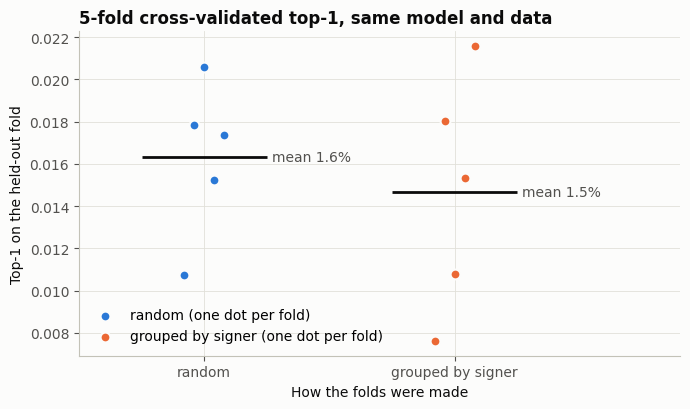

Takeaway: Random folds report 1.6% top-1 and signer-grouped folds 1.5%: the same model looks 0.2 points better when test signers also appear in training. Fold-to-fold sd is 0.006 for grouped folds, which hold different people, and 0.004 for random folds.

In [12]:
summary = runs.groupby("scheme")[["top1", "top5"]].agg(["mean", "std"])
display(summary.round(3))
gap = 100 * (summary.loc["random", ("top1", "mean")] - summary.loc["grouped by signer", ("top1", "mean")])

fig, ax = plt.subplots(figsize=(7, 4.2))
for i, (scheme, colour) in enumerate(zip(folds, (BLUE, ORANGE))):
    values = runs.loc[runs["scheme"] == scheme, "top1"]
    ax.scatter(np.full(len(values), i) + np.linspace(-0.08, 0.08, len(values)), values, color=colour, s=50, zorder=3,
               edgecolor=SURFACE, linewidth=1.5, label=f"{scheme} (one dot per fold)")
    ax.hlines(values.mean(), i - 0.25, i + 0.25, color=INK, linewidth=2)
    ax.annotate(f"mean {values.mean():.1%}", (i + 0.27, values.mean()), va="center", color=INK_2)
ax.set_xticks([0, 1], list(folds))
ax.set(title="5-fold cross-validated top-1, same model and data", xlabel="How the folds were made", ylabel="Top-1 on the held-out fold",
       xlim=(-0.5, 1.9))
ax.legend(loc="lower left")
plt.tight_layout()
plt.show()
takeaway(f"Random folds report {summary.loc['random', ('top1', 'mean')]:.1%} top-1 and signer-grouped folds "
         f"{summary.loc['grouped by signer', ('top1', 'mean')]:.1%}: the same model looks {abs(gap):.1f} points "
         f"{'better' if gap > 0 else 'worse'} when test signers also appear in training. Fold-to-fold sd is {summary.loc['grouped by signer', ('top1', 'std')]:.3f} for grouped "
         f"folds, which hold different people, and {summary.loc['random', ('top1', 'std')]:.3f} for random folds.")

The repository behind this series found the same gap with a held-out test set instead of cross-validation. In its committed results (`results/tables/test_fp32_summary.csv`), its temporal CNN (on the v1 input with 7 pose points instead of 17) scored 80.7% top-1 on a stratified random split (one seed, 8,755 test sequences) and 62.5% (mean of three seeds, sd 0.2) on four held-out signers (16,242 test sequences). Those two test sets differ in size and content, which the cross-validation above avoids.

## 5. Signer by signer

Every sequence has one out-of-fold prediction per scheme, so each signer gets two accuracies: one from a fold where their other clips were in training, and one from a fold where none were.

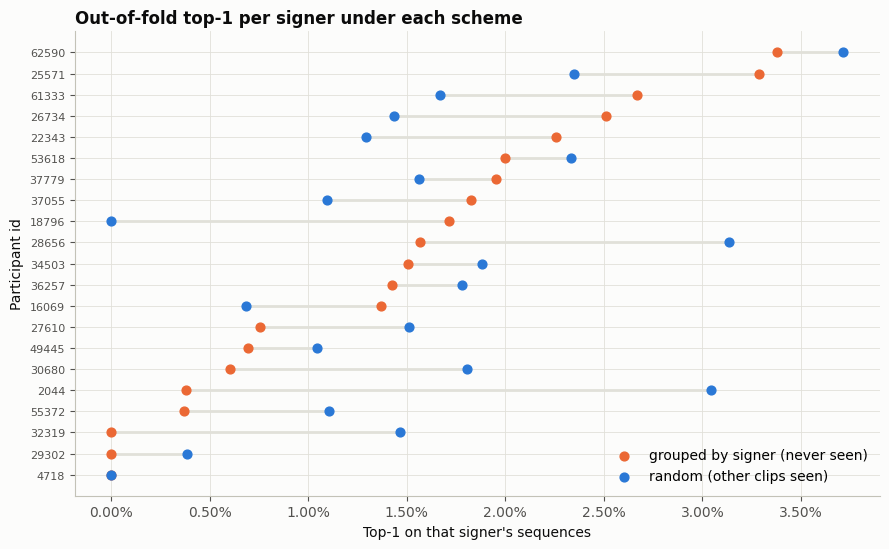

Takeaway: 12 of 21 signers score higher under random folds (random minus grouped runs from -1.7 to 2.7 points); as unseen signers they range from 0.0% to 3.4%, a spread a random split hides.

In [13]:
from matplotlib.ticker import PercentFormatter

correct = {scheme: predictions[scheme] == rows["label"].to_numpy() for scheme in folds}
per_signer = pd.DataFrame({scheme: pd.Series(c).groupby(signers).mean() for scheme, c in correct.items()})
per_signer["gain"] = 100 * (per_signer["random"] - per_signer["grouped by signer"])
per_signer = per_signer.sort_values("grouped by signer")

fig, ax = plt.subplots(figsize=(9, 5.6))
yy = np.arange(len(per_signer))
ax.hlines(yy, per_signer["grouped by signer"], per_signer["random"], color=GRID, linewidth=2, zorder=1)
ax.scatter(per_signer["grouped by signer"], yy, color=ORANGE, s=40, zorder=3, label="grouped by signer (never seen)")
ax.scatter(per_signer["random"], yy, color=BLUE, s=40, zorder=3, label="random (other clips seen)")
ax.set_yticks(yy, per_signer.index.astype(str), fontsize=8)
ax.set(title="Out-of-fold top-1 per signer under each scheme", xlabel="Top-1 on that signer's sequences", ylabel="Participant id")
ax.xaxis.set_major_formatter(PercentFormatter(1.0))
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()
higher = int((per_signer["gain"] > 0).sum())
takeaway(f"{higher} of {len(per_signer)} signers score higher under random folds (random minus grouped runs from "
         f"{per_signer['gain'].min():.1f} to {per_signer['gain'].max():.1f} points); as unseen signers they range from "
         f"{per_signer['grouped by signer'].min():.1%} to {per_signer['grouped by signer'].max():.1%}, a spread a random split hides.")

## 6. Where the gap comes from

Under random folds, a test clip usually has siblings in training: other clips of the same sign by the same signer. The next cell counts them for every test clip and groups accuracy by that count.

,top-1 (random folds),test clips
bucket,,
0,0.018,2368
1-2,0.014,2905
3-5,0.023,263
6-9,NaN,0
10+,NaN,0


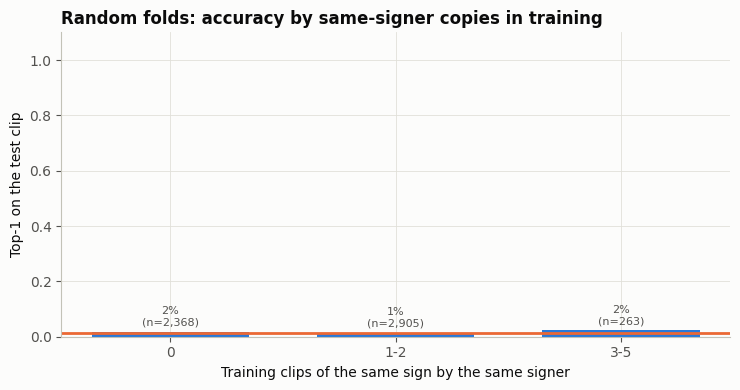

Takeaway: 57% of random-fold test clips have at least one same-signer, same-sign clip in training; clips with none score 1.8% and clips with 3-5 such copies score 2.3% (n = 263), against 1.5% for truly unseen signers.

In [14]:
fold = folds["random"]
pairs = pd.DataFrame({"signer": signers, "label": rows["label"].to_numpy(), "fold": fold})
total = pairs.groupby(["signer", "label"])["fold"].transform("size")
in_fold = pairs.groupby(["signer", "label", "fold"])["fold"].transform("size")
siblings = (total - in_fold).to_numpy()  # Same signer, same sign, in the training folds.
bins = [-1, 0, 2, 5, 9, np.inf]
names = ["0", "1-2", "3-5", "6-9", "10+"]
bucket = pd.cut(siblings, bins=bins, labels=names)
by_bucket = pd.DataFrame({"correct": correct["random"], "bucket": bucket}).groupby("bucket", observed=False)["correct"].agg(["mean", "size"])
display(by_bucket.rename(columns={"mean": "top-1 (random folds)", "size": "test clips"}).round(3))

fig, ax = plt.subplots(figsize=(7.5, 4))
bars = ax.bar(names, by_bucket["mean"], color=BLUE, width=0.7)
ax.bar_label(bars, labels=[f"{m:.0%}\n(n={n:,})" if n else "no clips" for m, n in zip(by_bucket["mean"], by_bucket["size"])], padding=3, fontsize=8, color=INK_2)
grouped_mean = correct["grouped by signer"].mean()
ax.axhline(grouped_mean, color=ORANGE, linewidth=2)
ax.annotate(f"grouped folds: {grouped_mean:.0%}", (len(names) - 0.6, grouped_mean), xytext=(0, 5), textcoords="offset points",
            ha="right", color=INK_2)
ax.set(title="Random folds: accuracy by same-signer copies in training", xlabel="Training clips of the same sign by the same signer",
       ylabel="Top-1 on the test clip", ylim=(0, 1.1))
plt.tight_layout()
plt.show()
share_with = (siblings > 0).mean()
top_bucket = by_bucket[by_bucket["size"] > 0].index[-1]  # The bucket with the most siblings that has clips.
takeaway(f"{share_with:.0%} of random-fold test clips have at least one same-signer, same-sign clip in training; clips with none "
         f"score {by_bucket.loc['0', 'mean']:.1%} and clips with {top_bucket} such copies score {by_bucket.loc[top_bucket, 'mean']:.1%} "
         f"(n = {by_bucket.loc[top_bucket, 'size']:,}), against {grouped_mean:.1%} for truly unseen signers.")

The cover image is the per-signer comparison from section 5.

In [15]:
fig, ax = plt.subplots(figsize=(12.8, 7.2))
ax.hlines(yy, per_signer["grouped by signer"], per_signer["random"], color=GRID, linewidth=3, zorder=1)
ax.scatter(per_signer["grouped by signer"], yy, color=ORANGE, s=90, zorder=3, label="signer never seen in training")
ax.scatter(per_signer["random"], yy, color=BLUE, s=90, zorder=3, label="random split: other clips of the signer in training")
ax.set_yticks(yy, per_signer.index.astype(str), fontsize=10)
ax.set_xlabel("Top-1 on that signer's sequences", fontsize=12)
ax.xaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_ylabel("Participant id", fontsize=12)
ax.set_title(f"Same model, two kinds of 5-fold split: random {summary.loc['random', ('top1', 'mean')]:.1%} top-1, "
             f"grouped by signer {summary.loc['grouped by signer', ('top1', 'mean')]:.1%}", fontsize=16, pad=14)
ax.legend(loc="lower right", fontsize=11)
plt.tight_layout()
save_cover(fig)
plt.close(fig)

## 7. What we found

In [16]:
display(Markdown(
    f"With the same model, data, recipe and {EPOCHS} epochs, random 5-fold cross-validation reports "
    f"{summary.loc['random', ('top1', 'mean')]:.1%} top-1 and signer-grouped cross-validation "
    f"{summary.loc['grouped by signer', ('top1', 'mean')]:.1%}, a gap of {gap:.1f} points. "
    f"{higher} of {len(per_signer)} signers look better under random folds, and as unseen signers their accuracy spans "
    f"{per_signer['grouped by signer'].min():.1%} to {per_signer['grouped by signer'].max():.1%}. "
    f"{share_with:.0%} of random-fold test clips have a same-signer copy of the same sign in training; clips with no such "
    f"copy score {by_bucket.loc['0', 'mean']:.1%} and clips with {top_bucket} copies {by_bucket.loc[top_bucket, 'mean']:.1%}. "
    "The grouped number is the one to report for a model meant to work for signers it has not seen."
))

With the same model, data, recipe and 2 epochs, random 5-fold cross-validation reports 1.6% top-1 and signer-grouped cross-validation 1.5%, a gap of 0.2 points. 12 of 21 signers look better under random folds, and as unseen signers their accuracy spans 0.0% to 3.4%. 57% of random-fold test clips have a same-signer copy of the same sign in training; clips with no such copy score 1.8% and clips with 3-5 copies 2.3%. The grouped number is the one to report for a model meant to work for signers it has not seen.

### Limitations

- One architecture and a fixed 25-epoch schedule; a larger model might memorise signers more, or less.
- Five grouped folds of four or five signers each give only five estimates, so the grouped mean has a wide uncertainty.
- Random-fold clips with no same-signer sibling are rare and may be unusual clips, so that bucket is not a clean estimate of unseen-signer accuracy.

### Ideas to try

- Leave-one-signer-out cross-validation: 21 folds, one estimate per signer.
- Plot grouped accuracy against the number of training signers to see how much a new signer would help.
- Repeat with the CNN + Transformer hybrid from notebook 4 and check whether the gap grows with model size.

### The series

- [1. ASL Signs EDA: animating 94k landmark sequences](https://www.kaggle.com/code/swapnilshukla007/asl-signs-eda-animating-94k-landmark-sequences)
- [2. The hand-swap bug: measuring train-serve skew in MediaPipe sign recognition](https://www.kaggle.com/code/swapnilshukla007/the-hand-swap-bug-train-serve-skew-in-asl-models)
- [4. A CNN + Transformer hybrid for isolated sign recognition in PyTorch](https://www.kaggle.com/code/swapnilshukla007/cnn-transformer-hybrid-for-isolated-asl-signs)
- [5. From PyTorch to the browser: ONNX export, FP16/INT8 quantization and temperature calibration](https://www.kaggle.com/code/swapnilshukla007/pytorch-to-browser-onnx-fp16-int8-calibration)

If this helped, an upvote helps other people find it, and feedback in the comments is welcome.